# Tidal ellipses inside a real coastal current record

Actively reconstruct the full16822paired NOAA CO-OPS observations, using actual irregular times and both flow components. The independent original UTide result is a standard-method comparison, not true tidal ground truth. Data are NOAA public-domain measurements atcb1401; code implements the selected Codiga2011 **technical report** ordinary least-squares special case.

At each sample, complex currentz=u+iv is mean plus p exp(+iωτ)+q exp(−iωτ) for each constituent. Hereu east,v north,cm/s;τhoursrelative to first/last midpoint. Fit all positive/negative harmonics jointly. No nodal/satellite modulation, Greenwich phase correction or linear trend is applied. The stationary90-day response includes a large residual from non-tidal and unresolved dynamics; it is never labeled full physical truth.

In [1]:
from pathlib import Path
import sys,time,json,numpy as np,matplotlib.pyplot as plt
from IPython.display import display
root=Path.cwd()if(Path.cwd()/'src').is_dir()else Path.cwd().parent;sys.path.insert(0,str(root))
from src.preprocessing import load_data,polar_to_velocity,CONSTITUENTS
from src.solvers import solve
from src.physics_model import ellipse_parameters,predict
from src.visualization import metrics,ellipse_plot
a=load_data(root/'data/raw_data.npz');t=a['time_seconds'];velocity=polar_to_velocity(a['speed'],a['direction_deg']);f=a['frequency_cph']
start=time.perf_counter();fresh,d=solve(t,velocity,f,return_diagnostics=True);runtime=time.perf_counter()-start
with np.load(root/'evaluation/baseline_reference.npz',allow_pickle=False)as b:original={k:b[k]for k in fresh}
upstream=json.loads((root/'notebooks/reference_outputs/upstream_measurements.json').read_text())
fitted=fresh['reconstruction'][0];residual=velocity-fitted;days=t/86400;plots={}
ellipse=ellipse_parameters(fresh['cosine'][0],fresh['sine'][0]);original_ellipse=ellipse_parameters(original['cosine'][0],original['sine'][0])
measurements={'fresh_runtime_seconds':runtime,'original_runtime_seconds':upstream['runtime_seconds'],'original_agreement':{k:metrics(fresh[k],original[k])for k in ('cosine','sine','reconstruction')},'relative_observation_l2':float(np.linalg.norm(residual)/np.linalg.norm(velocity)),'explained_total_squared_fraction':float(1-np.sum(residual**2)/np.sum(velocity**2)),'component_rms_residual_cm_s':np.sqrt(np.mean(residual**2,axis=1)).tolist(),'condition_number':float(np.linalg.cond(d['B'])),'normal_equation_relative_residual':float(np.linalg.norm(d['B'].conj().T@d['residual'])/(np.linalg.norm(d['B'])*np.linalg.norm(velocity)))}
print(json.dumps(measurements,indent=2))


{
  "fresh_runtime_seconds": 0.010922000044956803,
  "original_runtime_seconds": 0.024171800119802356,
  "original_agreement": {
    "cosine": {
      "ncc": 1.0,
      "nrmse": 0.0
    },
    "sine": {
      "ncc": 0.9999999999999998,
      "nrmse": 0.0
    },
    "reconstruction": {
      "ncc": 1.0000000000000002,
      "nrmse": 6.656842370637021e-17
    }
  },
  "relative_observation_l2": 0.4815991497355272,
  "explained_total_squared_fraction": 0.7680622589740174,
  "component_rms_residual_cm_s": [
    10.247258059379554,
    14.105697741724597
  ],
  "condition_number": 1.11034789604272,
  "normal_equation_relative_residual": 5.985667239082541e-16
}


## Measured vectors and actual stationary fit

Convert NOAA direction **towardflow**,clockwise fromtrue north, withu=speed*sin(direction),v=speed*cos(direction). Keep every returned pair and all real gaps. The left panels show the entire quarter; right panels show the firstthree days for legibility without changing the benchmark. A fitted harmonic flow is distinct from the full time-varying observation.

Parent visual QA: line segments are broken at observation gaps longer than720s (twice the nominal interval). NaN is used only in temporary display arrays; no measurement, reconstruction, metric or exact numeric trace is changed.

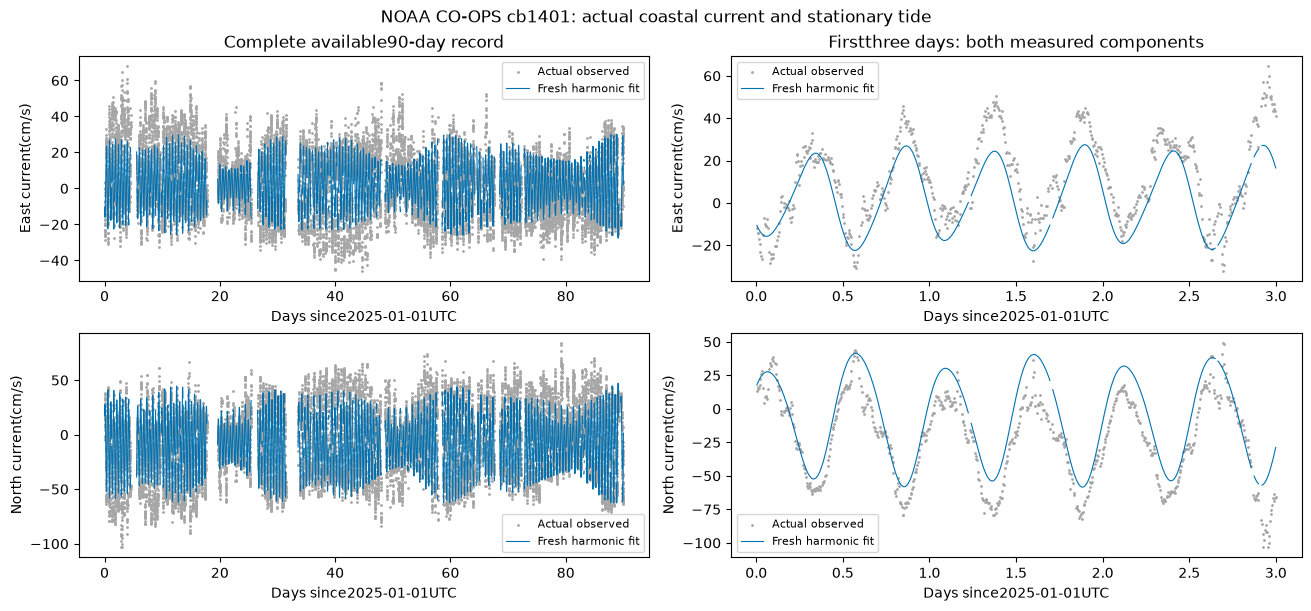

In [2]:
display_fit=fitted.copy();display_fit[:,np.r_[False,np.diff(t)>720]]=np.nan # display-only breaks, no imputed observations
fig,ax=plt.subplots(2,2,figsize=(13,6),layout='constrained');detail=days<3
for row,label in enumerate(('East','North')):
    for col,index in enumerate((np.arange(len(t)),np.flatnonzero(detail))):
        ax[row,col].scatter(days[index],velocity[row,index],s=1,color='.65',label='Actual observed');ax[row,col].plot(days[index],display_fit[row,index],lw=.8,color='#0072B2',label='Fresh harmonic fit');ax[row,col].set(xlabel='Days since2025-01-01UTC',ylabel=label+' current(cm/s)');ax[row,col].legend(fontsize=8)
ax[0,0].set_title('Complete available90-day record');ax[0,1].set_title('Firstthree days: both measured components');fig.suptitle('NOAA CO-OPS cb1401: actual coastal current and stationary tide')
plots['measured_fit']=fig;plt.close('all');display(fig)


## Eight constituent ellipses and harmonic energy

For each constituent,C=cEast+i*cNorth,S=sEast+i*sNorth,p=(C−iS)/2,q=(C+iS)/2. Majoraxis=|p|+|q|; signedminor=|p|−|q|, positivecounterclockwise. Inclination=[(argp+argq)/2]mod180degrees; rawphase=(inclination−argp)mod360. Weak or circular limits make the separate angle gauges unstable, so evaluation uses the complete Cartesian coefficients. Plotted arrows show actual progression in harmonic phase; no major/minor component is discarded. Energy below is half the squared coefficient sum (cm/s)², not a time-weighted transport flux.

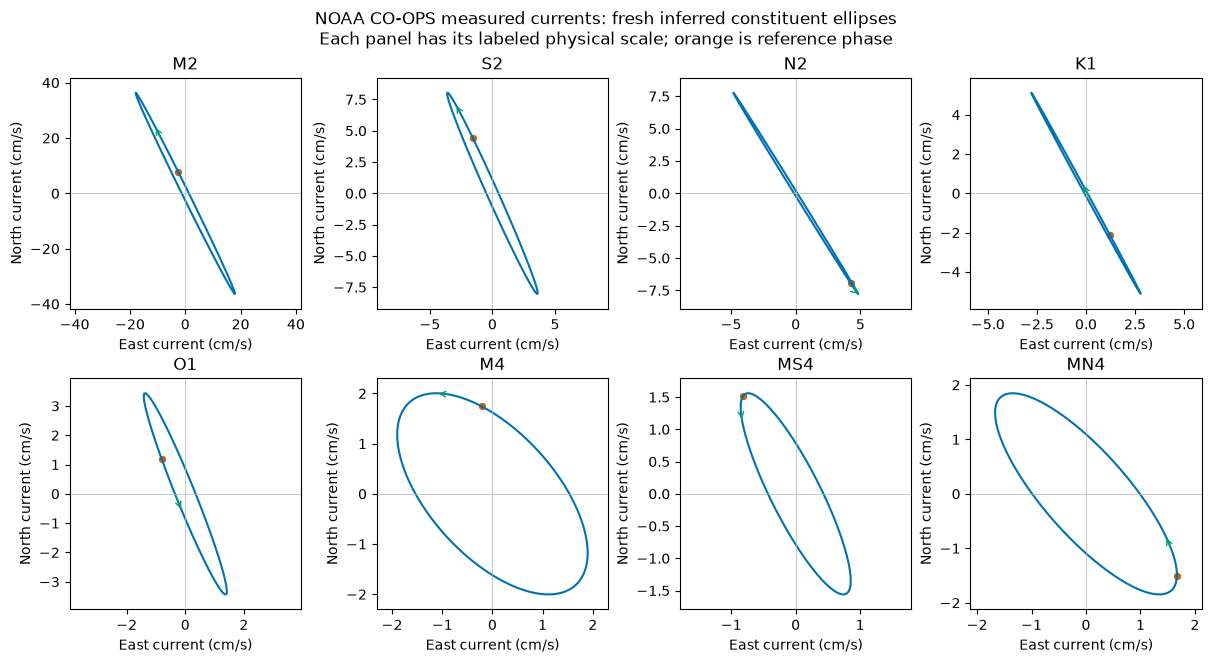

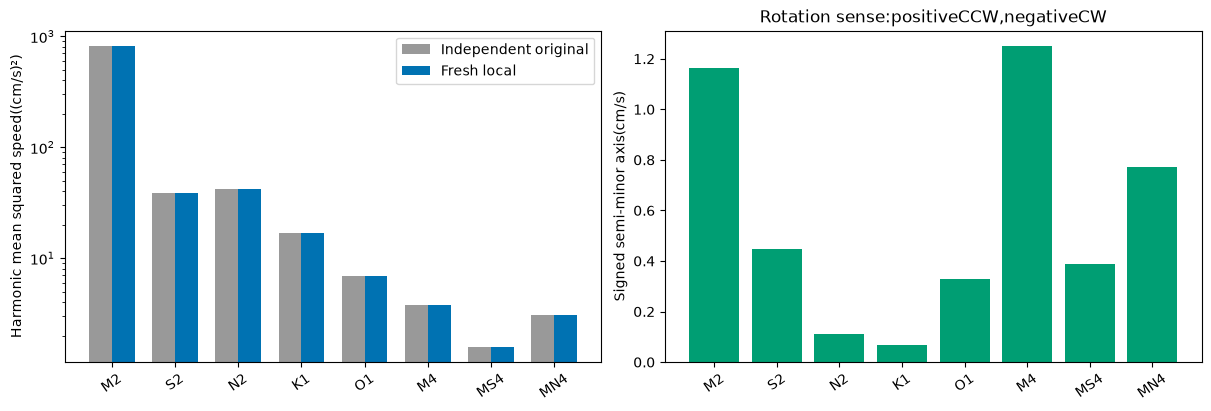

In [3]:
plots['ellipses']=ellipse_plot(fresh['cosine'][0],fresh['sine'][0],CONSTITUENTS);plt.close(plots['ellipses']);display(plots['ellipses'])
energy=.5*np.sum(fresh['cosine'][0]**2+fresh['sine'][0]**2,axis=0);original_energy=.5*np.sum(original['cosine'][0]**2+original['sine'][0]**2,axis=0)
fig,ax=plt.subplots(1,2,figsize=(12,4),layout='constrained');x=np.arange(8)
ax[0].bar(x-.18,original_energy,width=.36,label='Independent original',color='.6');ax[0].bar(x+.18,energy,width=.36,label='Fresh local',color='#0072B2');ax[0].set_yscale('log');ax[0].set_ylabel('Harmonic mean squared speed((cm/s)²)');ax[0].legend()
ax[1].bar(x,ellipse[:,1],color=['#009E73'if v>=0 else'#D55E00'for v in ellipse[:,1]]);ax[1].axhline(0,color='.3',lw=.7);ax[1].set(ylabel='Signed semi-minor axis(cm/s)',title='Rotation sense:positiveCCW,negativeCW')
for q in ax:q.set_xticks(x,CONSTITUENTS,rotation=35)
plots['harmonic_energy']=fig;plt.close(fig);display(fig)


## Real mismatch and missing acquisition

The stationary model explains about77% of the observed total squared current. The remaining~48% relativeL2residual is retained, not tuned away. Its time dependence can include weather-driven flow, discharge, local port dynamics, unmodeled harmonics and measurement error; these data alone cannot uniquely attribute causes. Compare velocity-space density, both residual distributions and actual gaps. No per-record QCflag was supplied in these APIrecords, so individual verification is not asserted.

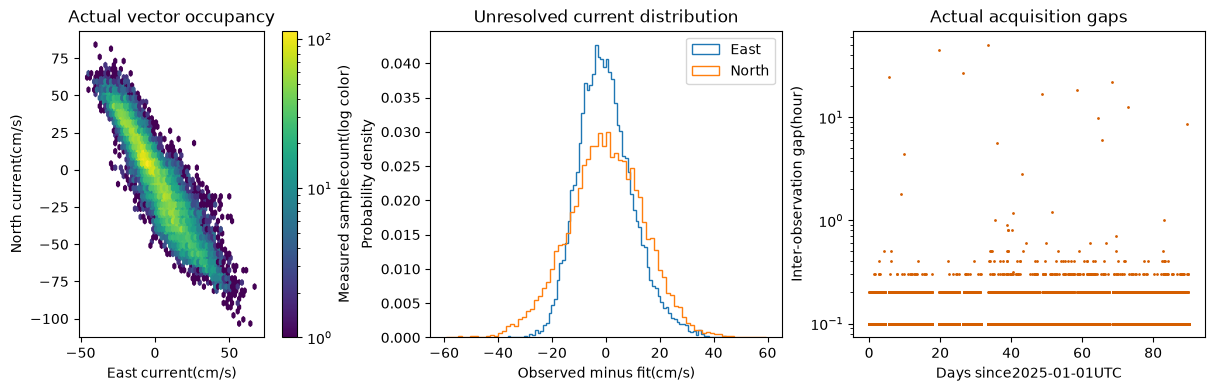

In [4]:
fig,ax=plt.subplots(1,3,figsize=(13,3.8),layout='constrained')
im=ax[0].hexbin(*velocity,gridsize=60,mincnt=1,cmap='viridis',bins='log');fig.colorbar(im,ax=ax[0],label='Measured samplecount(log color)');ax[0].set(xlabel='East current(cm/s)',ylabel='North current(cm/s)',title='Actual vector occupancy',aspect='equal')
for row,label in enumerate(('East','North')):ax[1].hist(residual[row],bins=80,histtype='step',density=True,label=label)
ax[1].set(xlabel='Observed minus fit(cm/s)',ylabel='Probability density',title='Unresolved current distribution');ax[1].legend()
gap=np.diff(t)/3600;ax[2].semilogy(days[1:],gap,'.',ms=2,color='#D55E00');ax[2].set(xlabel='Days since2025-01-01UTC',ylabel='Inter-observation gap(hour)',title='Actual acquisition gaps')
plots['residual_diagnostics']=fig;plt.close(fig);display(fig)


## Fresh acquisition sensitivity

Refit actual every-sixth observed pair, retaining its true timestamp, and independently fit the first30days. Predict both fitted models on the original full observation times. Every fit uses the same public astronomical frequencies and full-record raw-phase reference, so coefficient changes have physical meaning without arbitrary time-gauge shifts. Short-span fits can have larger coefficient uncertainty and poor out-of-span behavior; no uncertainty intervals are invented. The benchmark continues to use every available90-day observation.

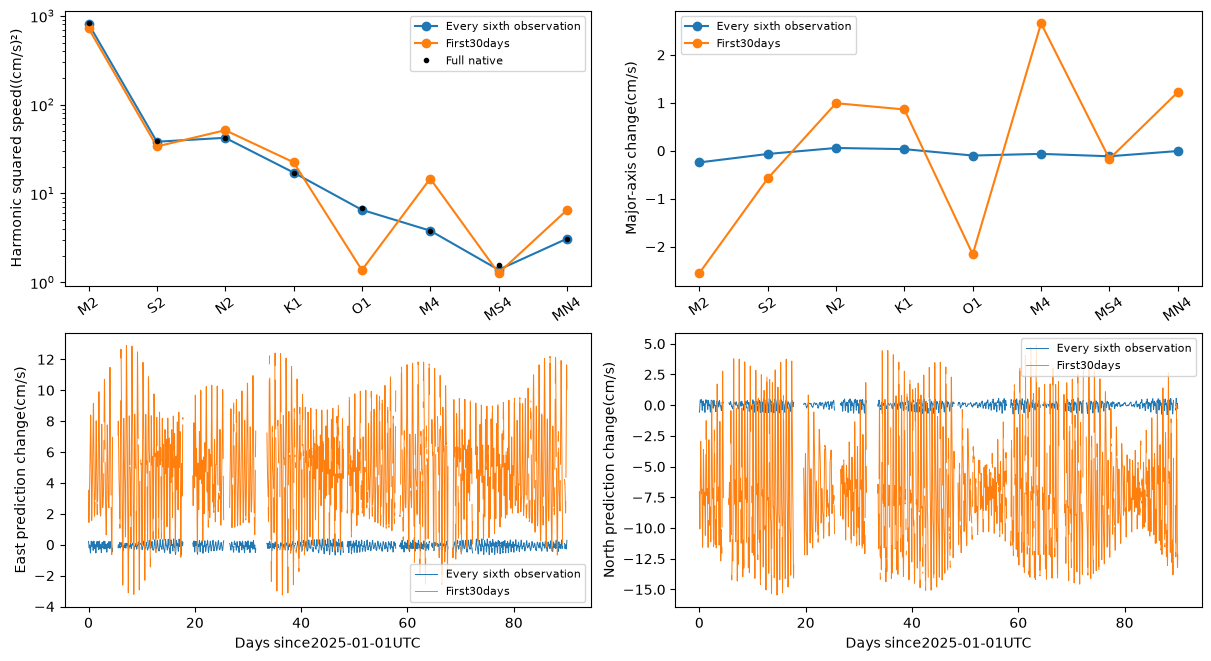

{
  "fresh_runtime_seconds": 0.010922000044956803,
  "original_runtime_seconds": 0.024171800119802356,
  "original_agreement": {
    "cosine": {
      "ncc": 1.0,
      "nrmse": 0.0
    },
    "sine": {
      "ncc": 0.9999999999999998,
      "nrmse": 0.0
    },
    "reconstruction": {
      "ncc": 1.0000000000000002,
      "nrmse": 6.656842370637021e-17
    }
  },
  "relative_observation_l2": 0.4815991497355272,
  "explained_total_squared_fraction": 0.7680622589740174,
  "component_rms_residual_cm_s": [
    10.247258059379554,
    14.105697741724597
  ],
  "condition_number": 1.11034789604272,
  "normal_equation_relative_residual": 5.985667239082541e-16,
  "acquisition_sensitivity": {
    "Every sixth observation": {
      "full_record_prediction_l2": 0.010676344601343623,
      "observation_l2": 0.4816900332071219
    },
    "First30days": {
      "full_record_prediction_l2": 0.31414160612091646,
      "observation_l2": 0.5547377088754136
    }
  }
}


In [5]:
subsets={'Every sixth observation':np.arange(len(t))[::6],'First30days':np.flatnonzero(days<30)};variants={};variant_predictions={}
for label,idx in subsets.items():
    r=solve(t[idx],velocity[:,idx],f,reference_days=d['reference_days']);variants[label]=r;variant_predictions[label]=predict(t,f,r['cosine'][0],r['sine'][0],r['mean_current'][0],d['reference_days'])
measurements['acquisition_sensitivity']={label:{'full_record_prediction_l2':float(np.linalg.norm(pred-fitted)/np.linalg.norm(fitted)),'observation_l2':float(np.linalg.norm(pred-velocity)/np.linalg.norm(velocity))}for label,pred in variant_predictions.items()}
fig,ax=plt.subplots(2,2,figsize=(12,6.5),layout='constrained')
for label,r in variants.items():
    en=.5*np.sum(r['cosine'][0]**2+r['sine'][0]**2,axis=0);ax[0,0].plot(np.arange(8),en,'o-',label=label);ax[0,1].plot(np.arange(8),ellipse_parameters(r['cosine'][0],r['sine'][0])[:,0]-ellipse[:,0],'o-',label=label)
    display_delta=variant_predictions[label]-fitted;display_delta[:,np.r_[False,np.diff(t)>720]]=np.nan
    for row in range(2):ax[1,row].plot(days,display_delta[row],lw=.7,label=label)
ax[0,0].plot(np.arange(8),energy,'k.',label='Full native');ax[0,0].set_yscale('log');ax[0,0].set_ylabel('Harmonic squared speed((cm/s)²)');ax[0,1].set_ylabel('Major-axis change(cm/s)')
for q in ax[0]:q.set_xticks(np.arange(8),CONSTITUENTS,rotation=35);q.legend(fontsize=8)
for row,label in enumerate(('East','North')):ax[1,row].set(xlabel='Days since2025-01-01UTC',ylabel=label+' prediction change(cm/s)');ax[1,row].legend(fontsize=8)
plots['acquisition_sensitivity']=fig;plt.close(fig);display(fig);print(json.dumps(measurements,indent=2))


## Independent evaluator and interpretation

The nextcell scores every full saved array and both current components. Baseline agreement checks faithful numerical extraction; analytic gappy harmonic recovery, rotary conversion, signed ellipse rotation and the adjoint/normal equations independently validate the mathematics. These checks do not imply that a stationary tide model explains storms or other non-tidal flows. Raw-phase/no-node configuration is the explicitly selected technical-report special case, not the full astronomical-correction method.

In [6]:
import importlib.util,tempfile
spec=importlib.util.spec_from_file_location('judge',root/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
with tempfile.TemporaryDirectory()as directory:
    path=Path(directory)/'fresh.npz';np.savez_compressed(path,**fresh);report,status=judge.evaluate(path)
assert status==0;print(json.dumps(report,indent=2))


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "cosine_0_ncc": 0.9999999999999998,
    "cosine_0_nrmse": 0.0,
    "cosine_1_ncc": 0.9999999999999998,
    "cosine_1_nrmse": 0.0,
    "sine_0_ncc": 1.0,
    "sine_0_nrmse": 0.0,
    "sine_1_ncc": 1.0,
    "sine_1_nrmse": 0.0,
    "reconstruction_0_ncc": 1.0,
    "reconstruction_0_nrmse": 1.0161057116382728e-16,
    "reconstruction_1_ncc": 1.0,
    "reconstruction_1_nrmse": 7.753476974417697e-17,
    "mean_absolute_error": 0.0
  },
  "thresholds": {
    "cosine_0_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "cosine_0_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "cosine_1_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "cosine_1_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "sine_0_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "sine_0_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
   